In [3]:
!python -m spacy download es_core_news_sm

     ---------------------------------------- 0.0/12.9 MB ? eta -:--:--
     ------------ --------------------------- 3.9/12.9 MB 27.2 MB/s eta 0:00:01
     ------------------------------- ------- 10.5/12.9 MB 29.4 MB/s eta 0:00:01
     ---------------------------------------- 12.9/12.9 MB 24.5 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')


In [2]:
import re
import pandas as pd
import spacy
from spacy import displacy
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from collections import Counter
from nltk.collocations import (BigramCollocationFinder, TrigramCollocationFinder,
                               BigramAssocMeasures, TrigramAssocMeasures)


nlp = spacy.load("es_core_news_sm")

FILE   = "../data/raw/unison_notas.parquet"
df = pd.read_parquet(FILE).set_index('id')
df['published'] = pd.to_datetime(df['published'])
df['year'] = df['published'].dt.year
df.sample(5)

,headline,published,text,author,scraped_at,year
id,,,,,,
15530,Inician actividades de la XVIII Semana de Arqu...,2013-09-23,"El rector de la Universidad de Sonora, Heribe...",NaN,2026-11-01T19:36:26.419638+00:00,2013
13103,Concluye huelga en Unison,2012-05-16,"Con 1,118 votos a favor, 181 en contra y 17 n...",NaN,2026-11-01T18:33:32.171884+00:00,2012
23072,Alumnos asesorados por docentes de Unison gana...,2016-11-25,"Dos medallas de plata, una de bronce y una me...",NaN,2026-11-01T22:49:46.897860+00:00,2016
25983,Promueve Unison el registro de patentes y prop...,2018-03-29,Ante la importancia de proteger la propiedad ...,NaN,2026-11-02T00:04:54.875587+00:00,2018
21377,Imparten plática sobre administración de recur...,2016-03-19,Con el propósito de fortalecer la formación i...,NaN,2026-11-01T22:07:00.629198+00:00,2016


In [ ]:
doc = nlp(df.sample().text.values[0])
displacy.render(doc, style="ent")

In [3]:
def headline_info(h):
    doc = nlp(h)
    first = doc[0]
    return pd.Series({"first_pos": first.pos_, "first_lemma": first.lemma_.lower()})

df[["first_pos", "first_lemma"]] = df["headline"].apply(headline_info)
print(df.groupby("year")["first_pos"].value_counts(normalize=True).unstack())

first_pos       ADJ       ADP       ADV       AUX     CCONJ       DET  \
year                                                                    
2012       0.009377  0.006028  0.009377  0.024782  0.000670  0.017415   
2013       0.011058  0.016324  0.009479  0.032649  0.000527  0.028963   
2014       0.015435  0.014032  0.009822  0.024790  0.000468  0.042563   
2015       0.019773  0.021456  0.016407  0.025663  0.000841  0.037863   
2016       0.013265  0.019683  0.015404  0.023962  0.001284  0.074454   
2017       0.014133  0.021930  0.016082  0.024366  0.000487  0.093567   
2018       0.017493  0.025753  0.012634  0.017007       NaN  0.073858   
2019       0.017432  0.027891  0.008716  0.020337  0.000581  0.093550   
2020       0.019547  0.019547  0.013374  0.018519       NaN  0.072016   
2021       0.015251  0.032680  0.005084  0.026144       NaN  0.077705   
2022       0.017123  0.057078  0.011416  0.026256       NaN  0.095890   

first_pos      INTJ      NOUN       NUM      PRON 

In [6]:
def mattr(words, window=100):
    """Moving-average type-token ratio: lexical diversity that does NOT depend on text length."""
    if len(words) < window:
        return np.nan
    ttrs = [len(set(words[i:i + window])) / window for i in range(0, len(words) - window + 1, 10)]
    return float(np.mean(ttrs))
lemmas, ents = [], []
docs_tokens = []
rows, first_sents, last_sents, all_sents = [], [], [], []
nlp.add_pipe("sentencizer")   # rule-based sentence splitting, fast
for doc in nlp.pipe(df["text"], batch_size=512, n_process=4):
    sents = [s for s in doc.sents if len(s.text.strip()) > 0]
    words = [t.lower_ for t in doc if t.is_alpha]
    sent_lens = [sum(t.is_alpha for t in s) for s in sents]
    rows.append({
        "n_words": len(words),
        "n_sents": len(sents),
        "mean_sent_len": np.mean(sent_lens) if sent_lens else np.nan,
        "ttr": len(set(words)) / len(words) if words else np.nan,   # biased by length, keep only for comparison
        "mattr": mattr(words),
    })
    if sents:
        first_sents.append(sents[0].text.strip())
        last_sents.append(sents[-1].text.strip())
        all_sents.extend(s.text.strip() for s in sents)

    lemmas.append([t.lemma_.lower() for t in doc
                   if t.is_alpha and not t.is_stop and len(t) > 2])
    ents.append([(e.text, e.label_) for e in doc.ents])
    docs_tokens.append([t.lower_ for t in doc if t.is_alpha])

df["lemmas"] = lemmas
df["ents"] = ents
orgs = Counter(t for row in df["ents"] for t, l in row if (l == "LOC") or (l == "ORG"))
orgs.most_common(50)

[('Universidad de Sonora', 20401),
 ('México', 6726),
 ('Sonora', 5474),
 ('Universidad', 4106),
 ('Hermosillo', 3748),
 ('Departamento', 2431),
 ('Caborca', 2373),
 ('JAR', 2314),
 ('Navojoa', 2309),
 ('URS', 2158),
 ('Unidad Regional Sur', 1780),
 ('Posgrado', 1768),
 ('Estados Unidos', 1549),
 ('Radio Universidad', 1496),
 ('Administración', 1250),
 ('Añadió', 1213),
 ('Unidad Regional Centro', 1173),
 ('División de Ciencias Económicas', 1144),
 ('Derecho', 1141),
 ('UNAM', 1040),
 ('Nogales', 1018),
 ('Administración Pública', 952),
 ('Centro', 947),
 ('Investigación', 941),
 ('Recordó', 895),
 ('Sociales', 891),
 ('URN', 889),
 ('Unidad Regional Norte', 879),
 ('España', 877),
 ('Departamento de Ciencias Químico Biológicas', 858),
 ('Psicología', 846),
 ('Departamento de Física', 845),
 ('Departamento de Derecho', 835),
 ('Unison', 833),
 ('Además', 831),
 ('Estado de Sonora', 824),
 ('Departamento de Investigación', 795),
 ('Matemáticas', 789),
 ('Música', 785),
 ('Salud', 768),


In [7]:
stop = nlp.Defaults.stop_words

def bad_edges(*w):
    return w[0] in stop or w[-1] in stop or len(w[0]) < 3 or len(w[-1]) < 3

def top_collocations(docs, n=2, measure="pmi", min_freq=10, top=30):
    if n == 2:
        finder = BigramCollocationFinder.from_documents(docs)   # doesn't cross document borders
        am = BigramAssocMeasures()
    else:
        finder = TrigramCollocationFinder.from_documents(docs)
        am = TrigramAssocMeasures()

    finder.apply_freq_filter(min_freq)       # PMI overrates rare pairs, so always set a min frequency
    finder.apply_ngram_filter(bad_edges)

    score_fn = {"pmi": am.pmi, "llr": am.likelihood_ratio}[measure]
    rows = [(" ".join(g), s, finder.ngram_fd[g]) for g, s in finder.score_ngrams(score_fn)[:top]]
    return pd.DataFrame(rows, columns=["ngram", measure, "freq"])

bi_pmi  = top_collocations(docs_tokens, n=2, measure="pmi")
bi_llr  = top_collocations(docs_tokens, n=2, measure="llr")
tri_llr = top_collocations(docs_tokens, n=3, measure="llr", min_freq=5)

print(bi_pmi.head(15))
print(bi_llr.head(15))
print(tri_llr.head(15))
df["tokens"] = docs_tokens
for year, g in df.groupby("year"):
    print(year, top_collocations(g["tokens"].tolist(), min_freq=5, measure="llr", top=10), sep="\n")

                   ngram        pmi  freq
0          leona vicario  19.614891    10
1    trespalacios argain  19.614891    10
2           pagés blanch  19.477387    10
3     quiatora monorriel  19.351856    11
4           arnaldo coen  19.236379    11
5   constellation brands  19.236379    12
6          iloki assanga  19.236379    12
7        pauline viardot  19.236379    11
8       xenophon moussas  19.236379    11
9            turro breff  19.129464    14
10        sabine pirchio  19.110848    11
11      marincic lovriha  19.029928    13
12            emil volek  19.013987    12
13       motomichi inoue  19.013987    12
14        oyes escúchame  19.003933    11
                      ngram           llr  freq
0           unidad regional  70338.350591  5303
1                alma mater  41928.164517  2563
2        educación superior  32677.241544  2730
3               máxima casa  27817.769562  2018
4              regional sur  27614.310486  2294
5       velázquez contreras  26860.15888

Topic 0: economía, económico, méxico, social, país, gobierno, política, desarrollo, empresa, cambio
Topic 1: unidad, unidad regional, regional, urs, campus, sur, navojoa, ciencias, regional sur, división
Topic 2: música, obra, teatro, artes, danza, historia, festival, concierto, musical, presentar
Topic 3: mujer, género, violencia, hombre, equidad, igualdad, violencia género, perspectiva género, social, perspectiva
Topic 4: salud, enfermedad, cáncer, persona, medicina, enfermería, médico, alimento, paciente, físico
Topic 5: rector, institución, educación, universitario, superior, grijalva, grijalva monteverde, monteverde, educación superior, calidad
Topic 6: investigación, ingeniería, ciencia, proyecto, científico, posgrado, tecnología, investigador, física, área
Topic 7: examen, aspirante, curso, alumno, licenciatura, semestre, ingreso, inscripción, hora, evaluación
Topic 8: derecho, penal, justicia, sistema, mediación, jurídico, oral, derechos, sistema justicia, derechos humanos
Topi

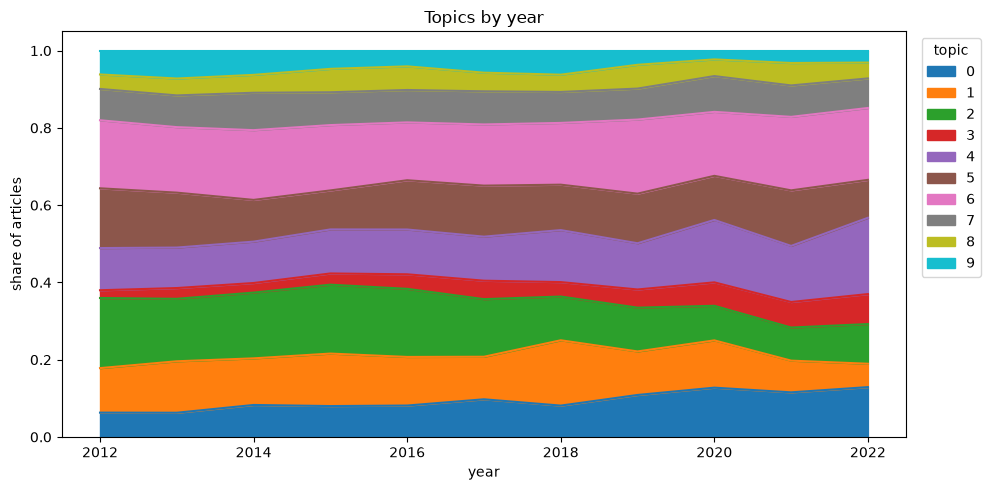

topic           0     1     2     3     4     5     6     7     8     9
first_lemma                                                            
alumnos      0.02  0.27  0.22  0.02  0.11  0.02  0.15  0.15  0.02  0.02
destacar     0.14  0.07  0.07  0.02  0.15  0.07  0.29  0.07  0.03  0.08
el           0.19  0.03  0.14  0.06  0.17  0.09  0.15  0.04  0.08  0.06
iniciar      0.05  0.13  0.13  0.02  0.08  0.13  0.16  0.17  0.08  0.05
invitar      0.06  0.06  0.16  0.02  0.12  0.04  0.27  0.18  0.04  0.06
ofrecer      0.05  0.22  0.26  0.04  0.10  0.03  0.07  0.16  0.08  0.00
participar   0.05  0.27  0.12  0.04  0.10  0.06  0.19  0.04  0.05  0.06
presentar    0.10  0.05  0.40  0.05  0.06  0.07  0.18  0.03  0.04  0.02
realizar     0.05  0.27  0.09  0.06  0.17  0.06  0.17  0.05  0.06  0.03
él           0.07  0.13  0.12  0.03  0.11  0.18  0.17  0.09  0.04  0.06


In [8]:
# 1) Build the document-term matrix from the lemmas already computed with spaCy
corpus = df["lemmas"].apply(" ".join)

# Words that appear in nearly every article add no information; adjust to your corpus
domain_stop = ["universidad", "unison", "sonora", "hermosillo", "señalar", "indicar", "dijo"]

vec = TfidfVectorizer(
    min_df=10,          # ignore very rare words
    max_df=0.5,         # ignore words present in more than 50% of articles
    ngram_range=(1, 2), # include bigrams ("convenio colaboración")
    stop_words=domain_stop,
)
X = vec.fit_transform(corpus)
terms = vec.get_feature_names_out()

# 2) Fit NMF
k = 10
nmf = NMF(n_components=k, init="nndsvd", random_state=42, max_iter=500)
W = nmf.fit_transform(X)   # documents x topics
H = nmf.components_        # topics x terms

# 3) Top words per topic
def show_topics(H, terms, n=10):
    for i, comp in enumerate(H):
        top = comp.argsort()[::-1][:n]
        print(f"Topic {i}: {', '.join(terms[top])}")

show_topics(H, terms)

# 4) Dominant topic per article
df["topic"] = W.argmax(axis=1)
df["topic_weight"] = W.max(axis=1)
print(df["topic"].value_counts(normalize=True).sort_index())

# 5) Topics over time (share of articles per year)
topic_year = pd.crosstab(df["year"], df["topic"], normalize="index")
topic_year.plot.area(figsize=(10, 5), colormap="tab10")
plt.ylabel("share of articles"); plt.title("Topics by year")
plt.legend(title="topic", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

# 6) Topics vs. headline verb (needs first_lemma from the headline step)
top_verbs = df["first_lemma"].value_counts().head(10).index
verb_topic = pd.crosstab(df[df["first_lemma"].isin(top_verbs)]["first_lemma"],
                         df["topic"], normalize="index")
print(verb_topic.round(2))

        n_words   n_sents  mean_sent_len     mattr  headline_len
count  19300.00  19300.00       19230.00  19220.00      19300.00
mean     416.02     10.33          40.70      0.69         11.26
std      202.13      5.07           9.25      0.03          2.67
min        0.00      0.00           5.99      0.52          0.00
25%      286.00      7.00          35.27      0.67         10.00
50%      378.00      9.00          40.00      0.69         11.00
75%      497.00     12.00          45.33      0.71         13.00
max     3972.00    158.00         454.67      0.86         24.00


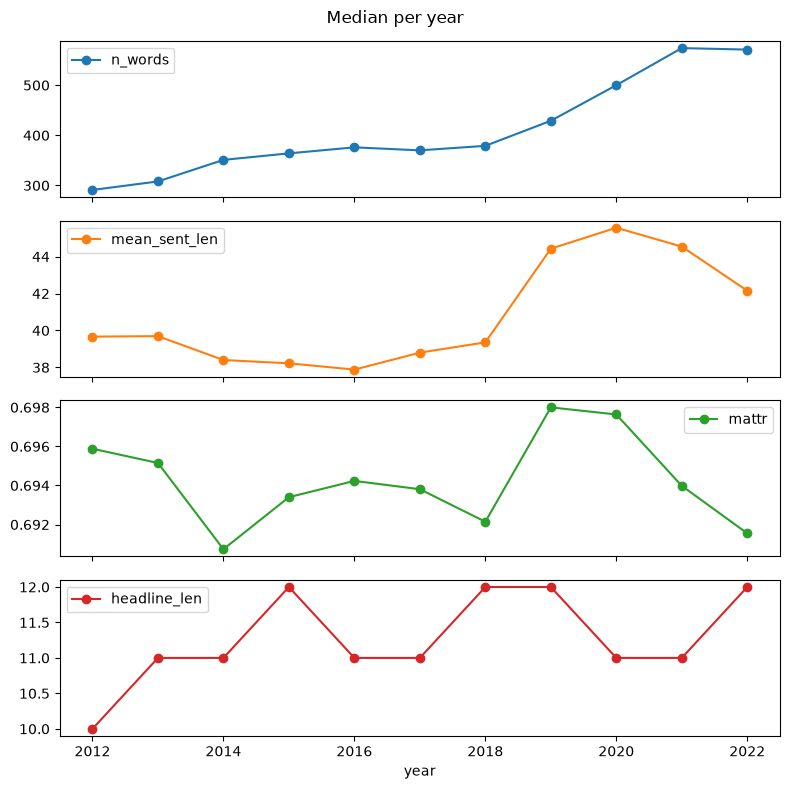

Top openings: [('la universidad de sonora', 705), ('con el objetivo de', 340), ('en el marco de', 287), ('en el marco del', 241), ('con el propósito de', 226), ('con la participación de', 207), ('como parte de las', 182), ('con la finalidad de', 151), ('con el fin de', 117), ('la unidad regional sur', 80), ('como parte de la', 74), ('', 70), ('como parte del programa', 66), ('el rector de la', 50), ('estudiantes de la licenciatura', 47)]
Top closings: [('la universidad de sonora', 183), ('', 70), ('universidad de sonora be', 43), ('radio uson mx be', 41), ('gaceta default htm agg', 38), ('mx medios_informativos desdelauniversidad eq', 35), ('casa de estudios jar', 33), ('de nuestra institución jar', 30), ('esta casa de estudios', 26), ('universidad de sonora cdm', 25), ('radio uson mx jar', 23), ('https procesorector unison mx', 23), ('universidad de sonora jar', 22), ('la entrada es gratuita', 21), ('universidad de sonora lma', 21)]
[('con', 2920), ('la', 2396), ('el', 1846), ('en', 1

In [9]:
stats = pd.DataFrame(rows, index=df.index)
df = df.join(stats)
df["headline_len"] = df["headline"].str.split().str.len()

print(df[["n_words", "n_sents", "mean_sent_len", "mattr", "headline_len"]].describe().round(2))

# Evolution over time
by_year = df.groupby("year")[["n_words", "mean_sent_len", "mattr", "headline_len"]].median()
by_year.plot(subplots=True, figsize=(8, 8), marker="o", title="Median per year")
plt.tight_layout(); plt.show()

# ---------- 2) Boilerplate: repeated openings and closings ----------
def first_k_words(text, k=4):
    return " ".join(re.findall(r"\w+", text.lower())[:k])

def last_k_words(text, k=4):
    return " ".join(re.findall(r"\w+", text.lower())[-k:])

openings = Counter(first_k_words(t) for t in df["text"])
closings = Counter(last_k_words(t) for t in df["text"])
print("Top openings:", openings.most_common(15))
print("Top closings:", closings.most_common(15))

# Typical first words of the first sentence (dateline, "Con motivo de...", etc.)
first_word = Counter(s.split()[0].lower() for s in first_sents if s.split())
print(first_word.most_common(15))

# ---------- 3) Boilerplate: sentences repeated across articles ----------
sent_counts = Counter(all_sents)
boiler = pd.DataFrame(
    [(s, c) for s, c in sent_counts.items() if c >= 5 and len(s.split()) >= 4],
    columns=["sentence", "n_articles"],
).sort_values("n_articles", ascending=False)
print(boiler.head(20).to_string())

# Share of articles containing at least one repeated sentence, by year
repeated = set(boiler["sentence"])
df["has_boiler"] = df["text"].apply(lambda t: any(s in t for s in repeated)) if repeated else False
print(df.groupby("year")["has_boiler"].mean().round(2))

verb
realizar      805
iniciar       662
participar    615
invitar       609
presentar     600
ofrecer       476
destacar      313
impartir      239
continuar     233
concluir      211
inaugurar     207
exponer       181
hablar        181
celebrar      180
recibir       174
reconocer     172
analizar      171
tener         169
obtener       163
entregar      141
Name: count, dtype: int64
subj
universidad de sonora    81
que                      51
convenio                 24
rector                   17
documento                10
convenio colaboración    10
quienes                   8
acuerdo                   8
“                         7
méxico                    7
rector universidad        6
quien                     5
unidad regional sur       5
convenio marco            5
máxima casa estudios      4
Name: count, dtype: int64
subj
que                          78
evento                       43
exposición                   19
quien                        15
jonathan castellón flores

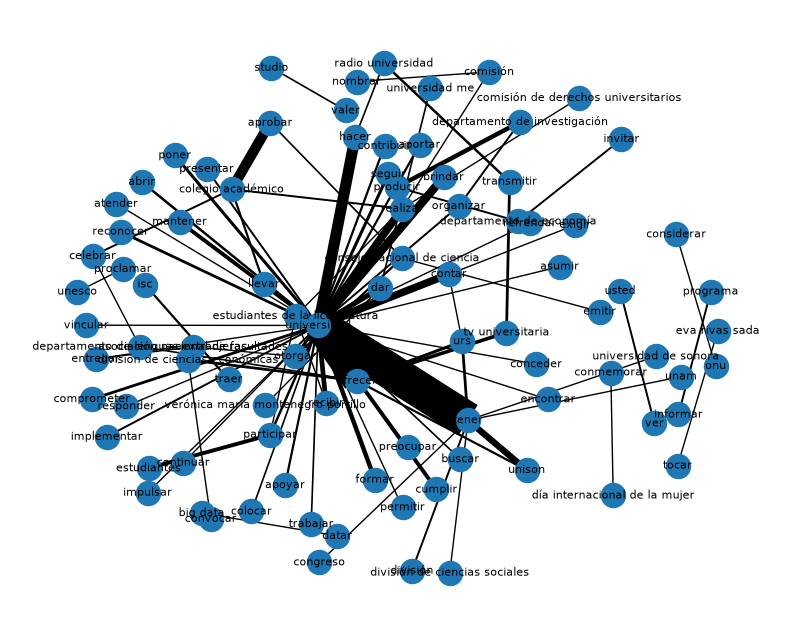

In [10]:
SUBJ = {"nsubj"}
PASS_SUBJ = {"nsubj:pass"}          # passive subject: the "patient", not the doer
OBJ = {"obj", "iobj"}
NP_MODS = {"flat", "flat:name", "amod", "nmod", "compound"}   # keep short noun phrases

def np_text(tok, doc):
    """Compact noun phrase: the head + direct modifiers, without relative clauses."""
    # if the head belongs to a named entity, use the whole entity
    for ent in doc.ents:
        if ent.start <= tok.i < ent.end:
            return ent.text, ent.label_
    toks = [tok] + [c for c in tok.children if c.dep_ in NP_MODS and abs(c.i - tok.i) <= 3]
    toks.sort(key=lambda t: t.i)
    return " ".join(t.text for t in toks), None

triples, hl_pairs = [], []

# ---------- 1) S-V-O from the article text ----------
for idx, doc in zip(df.index, nlp.pipe(df["text"], batch_size=50, n_process=2)):
    for tok in doc:
        if tok.pos_ != "VERB":
            continue
        subjs = [c for c in tok.children if c.dep_ in SUBJ]
        passv = [c for c in tok.children if c.dep_ in PASS_SUBJ]
        objs = [c for c in tok.children if c.dep_ in OBJ]
        if not (subjs or passv):
            continue
        for s in subjs or [None]:
            for o in objs or [None]:
                s_txt, s_ent = np_text(s, doc) if s is not None else (None, None)
                o_txt, o_ent = np_text(o, doc) if o is not None else (None, None)
                triples.append({
                    "id": idx, "year": df.at[idx, "year"], "verb": tok.lemma_.lower(),
                    "subj": s_txt, "subj_ent": s_ent, "obj": o_txt, "obj_ent": o_ent,
                    "voice": "active",
                })
        for p in passv:                                    # "El convenio fue firmado por..."
            p_txt, p_ent = np_text(p, doc)
            agent = [c for c in tok.children if c.dep_ in {"obl:agent", "obl"}
                     and any(ch.lemma_ == "por" for ch in c.children)]
            a_txt, a_ent = np_text(agent[0], doc) if agent else (None, None)
            triples.append({"id": idx, "year": df.at[idx, "year"], "verb": tok.lemma_.lower(),
                            "subj": a_txt, "subj_ent": a_ent, "obj": p_txt, "obj_ent": p_ent,
                            "voice": "passive"})

svo = pd.DataFrame(triples)

# ---------- 2) V-O from the headlines (subject is usually elided) ----------
for idx, doc in zip(df.index, nlp.pipe(df["headline"], batch_size=100)):
    root = next((t for t in doc if t.dep_ == "ROOT"), None)
    if root is not None and root.pos_ == "VERB":
        objs = [np_text(c, doc)[0] for c in root.children if c.dep_ in OBJ]
        hl_pairs.append({"id": idx, "year": df.at[idx, "year"],
                         "verb": root.lemma_.lower(), "obj": objs[0] if objs else None})
hl = pd.DataFrame(hl_pairs)

# ---------- 3) Analysis ----------
print(hl["verb"].value_counts().head(20))

# Who does X? (subjects of a given verb)
def who_does(verb, top=15, only_ent=None):
    q = svo[(svo["verb"] == verb) & svo["subj"].notna()]
    if only_ent:
        q = q[q["subj_ent"] == only_ent]
    return q["subj"].str.lower().value_counts().head(top)

print(who_does("firmar"))
print(who_does("inaugurar"))
print(who_does("firmar", only_ent="ORG"))

# What gets X? (objects of a given verb)
print(svo[(svo["verb"] == "firmar") & svo["obj"].notna()]["obj"].str.lower().value_counts().head(15))

# Verbs most associated with organizations as subjects
print(svo[svo["subj_ent"] == "ORG"]["verb"].value_counts().head(15))

# Verb x subject-type table (what kind of actor does what)
top_verbs = svo["verb"].value_counts().head(15).index
print(pd.crosstab(svo[svo["verb"].isin(top_verbs)]["verb"],
                  svo["subj_ent"].fillna("common noun"), normalize="index").round(2))

# Headline verbs over time
top_hl = hl["verb"].value_counts().head(8).index
print(pd.crosstab(hl["year"], hl["verb"])[top_hl])

edges = (svo[(svo["subj_ent"] == "ORG") & svo["subj"].notna()]
         .assign(subj=lambda d: d["subj"].str.lower())
         .groupby(["subj", "verb"]).size().reset_index(name="w").query("w >= 5"))
G = nx.from_pandas_edgelist(edges, "subj", "verb", edge_attr="w")
plt.figure(figsize=(10, 8))
nx.draw_networkx(G, pos=nx.spring_layout(G, seed=1, k=0.6), node_size=300, font_size=8,
                 width=[G[u][v]["w"] / 5 for u, v in G.edges])
plt.axis("off"); plt.show()